---
title: The spectrum plume model for the relationship between convection and the large-scale environment

author:
  - dongqi_lin
  - martin_singh
downloads:
  - file: ./spectral-plume-model.zip
    title: Download this recipe (.zip)
thumbnail: https://github.com/21centuryweather/Weather-Change-Cookbook/blob/main/recipes/spectral-plume-model/Plume_spectrum_Palmer_plane.png?raw=true
---

[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/21centuryweather/Weather-Change-Cookbook/binder-spectral-plume-model)	­

## Introduction

The relationship between convection and the large-scale environment is important for understanding how convection will change in a warmer climate and the two-way interactions between convection and the environment. In this recipe, we demonstrate the spectral plume model (SPM), which is developed by [Lin and Singh et al. (2026)](https://doi.org/10.5194/wcd-7-2193-2026) based on [Arakawa and Schubert (1974)](https://doi.org/10.1175/1520-0469(1974)031<0674:IOACCE>2.0.CO;2) and [Zhou and Xie (2019)](https://doi.org/10.1175/JAS-D-18-0330.1). 

The SPM considers the convective ensemble consisting of a spectrum of plumes with varying entrainment rates. We can use the SPM to relate the amount and intensity of convection to the mean thermodynamic profiles within a mesoscale region of the tropics. This recipe uses code from [plume_models](https://github.com/dongqi-DQ/plume_models/) repository. For more details, please see the published paper [Lin and Singh et al. (2026)](https://doi.org/10.5194/wcd-7-2193-2026).

The Scipy function for plotting may requie `scipy==1.16.2`. The `environment.yml` in the [plume_models](https://github.com/dongqi-DQ/plume_models/) repository can also be used if one wants to create the entire environment.

In [1]:
# All the thermodynamic functions are stored in precip_ext_model.py
# All the thermodynamic constants are stored in model_constants.py
from tqdm import tqdm                    ## package for progress bar
from multiprocess import Pool            ## package for parallel processing
import numpy as np
import pandas as pd
import os
## make the folders for storing the data and figures if not exists
folder_path = ["./Data","./Figures"]
for paths in folder_path:
    os.makedirs(paths, exist_ok=True)
from scipy.interpolate import griddata   ## package for interpolation and plotting
import matplotlib.pyplot as plt
from precip_ext_model import *           ## the SPM in Lin and Singh et al. (2026)

## Data

The SPM is a simple model that does not require additional data input. The function `spectral_plume_lcl` requires the following input:
```
>>>>
T_base   : Base temperature of plume (K);             default is 300 K
p_base   : Base pressure of plume (Pa);               default is 100000 Pa
RH       : Environmental relative humidity (unitless, between 0 and 1)
z_base   : Base height of plume (m);                  default is 50 m
z_lcl    : Cloud base height (m)
z_top    : Top height of the plume model (m);         default is 15000 m
P        : Mean precipitation rate in the mesoscale region (mm/day)
mprofile : Vertical profile of mass flux;             default is "cos"
>>>>
```
This function also allows users to:

```
>>>
get_plane : output data for plotting in the stability-humidity plane [True/False] (see further examples below)
plotting  : plot the vertical moist static energy profiles of the plume and the environment [True/False]
save_data : save a csv of all the data for the given set of input variables [True/False]
>>>
```

To replicate [Lin and Singh et al. (2026)](https://doi.org/10.5194/wcd-7-2193-2026), here we only vary `RH` for the dryness of the environment, `z_lcl` for different cloud base height, and `P` for varying precipitation rate. For example, for an environment with relative humidity of 80% (`RH=0.8`), cloud base of 700 m (`z_lcl=700`), and areal-mean precipitation rate of 24 mm day<sup>-1</sup> (or 0.5 mm h<sup>-1</sup>; `P=12`), we can get the plume moist static energy (MSE) profile as follows:  


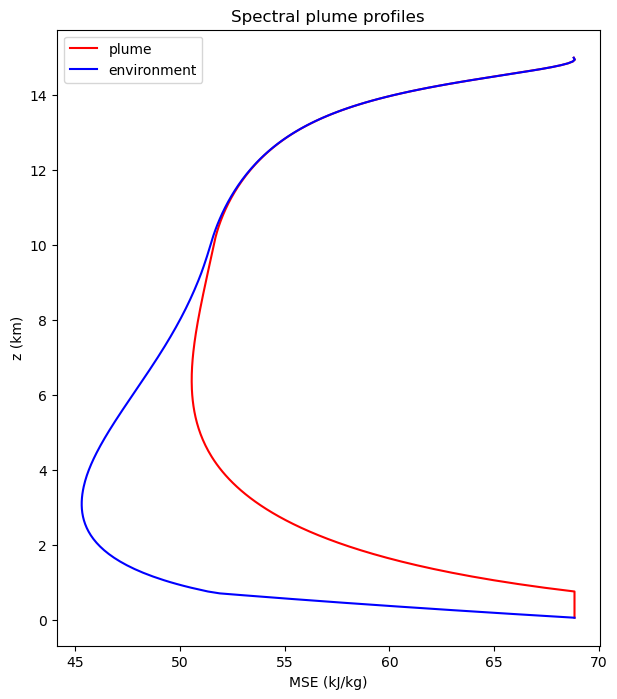

In [2]:
_ = spectral_plume_lcl(model_type="precip",z_lcl=700,RH=0.5,P=12,get_plane = False, plotting=True, save_data=False)

## Analysis

Now we want to plot the SPM results in the stability-humidity plane for varying `RH` and `P`. Again, `spectral_plume_lcl` is the key function, where one can get the predicted buoyancy and convective available potential energy (CAPE). We use the function `get_Palmer_plane` below, where `RH` is between 2% and 98% and `P` is between 0 and 1.25 mm h<sup>-1</sup> (or 30 mm day<sup>-1</sup>). This gives 775 pairs of plume and environment profiles, so we run things in parallel. Here we use 4 CPUs (`num_cpus = 4`). The SPM predictions will be saved as a CSV file in the `Data` folder named based on the given `z_lcl` and mass flux vertical profile. Here we use cloud base height of 1400 m with the `"cos"` profile as an example.

In [3]:
def get_Palmer_plane(z_lcl=1400,mprofile="cos",read_from_file=False):

    fname = f"Data/LCL_ext_{z_lcl}m_mprof-{mprofile}.csv"

    if os.path.exists(fname) & read_from_file:
       df = pd.read_csv(fname)
       return df

    # 1. Create (RH, P) pairs

    RH_values = np.linspace(0.02, 0.98, 25)
    P_values = np.linspace(0, 30, 31)


    param_pairs = [(RH, P) for RH in RH_values for P in P_values]

    # 2. Define worker function
    def worker(args):
        RH, P = args
        CAPE_u, CAPE_ext, dh, sat_def,dz,ent_b = spectral_plume_lcl(
            model_type="precip", RH=RH, P=P, z_lcl=z_lcl,mprofile=mprofile,
            get_plane=True, plotting=False, save_data=False
        )
        return CAPE_u, CAPE_ext, dh, sat_def, P, RH,dz,ent_b

    # 3. Run in parallel
    num_cpus = 4
    with Pool(processes=num_cpus) as pool:
        results = list(tqdm(pool.imap(worker, param_pairs), total=len(param_pairs)))


    # 4. Unpack results
    CAPEu_list, CAPEext_list, dh_list, sat_def_list, P_list,RH_list,dz_list,ent_b_list = zip(*results)
    CAPEu_list = list(CAPEu_list)
    CAPEext_list = list(CAPEext_list)
    dh_list = list(dh_list)
    sat_def_list = list(sat_def_list)
    P_list = list(P_list)
    RH_list = list(RH_list)
    dz_list = list(dz_list)
    ent_b_list = list(ent_b_list)

    # 5. Save to CSV
    df = pd.DataFrame({
        "CAPE_u":CAPEu_list,
        "CAPE_ext": CAPEext_list,
        "dh": dh_list,
        "sat_def": sat_def_list,
        "P": P_list,
        "RH": RH_list,
        "dz": dz_list,
        "ent_b":ent_b_list
                })
    df.to_csv(fname, index=False)

    return df

In [4]:
z_lcl = 1400
mprofile = "cos"
## If the data has already been generated, you can set read_from_file=True to read the data from the CSV file instead of recalculating it.
df = get_Palmer_plane(z_lcl,mprofile,read_from_file=False)

100%|██████████| 775/775 [02:29<00:00,  5.17it/s]


Now this DataFrame contains the SPM results. These are 775 data points and to make them a contour plot we use the following function based on Scipy:

In [5]:
## Scipy interpolate.griddata is used to interpolate scattered data onto a regular grid for contour plotting. 
def scatter_to_contour(x_in,y_in,z_in):
    # 1D scattered data
    x = np.asarray(x_in)
    y = np.asarray(y_in)
    z = np.asarray(z_in)

    # make regular grid
    xi = np.linspace(x.min(), x.max(), 100)
    yi = np.linspace(y.min(), y.max(), 100)
    Xi, Yi = np.meshgrid(xi, yi)

    # interpolate scattered data onto grid
    Zi = griddata((x, y), z, (Xi, Yi), method="linear")
    return Xi, Yi, Zi

In [6]:
## prepare arrays for plotting
sat_def_arr = np.array(df["sat_def"])*const.Lv0/1000
dh_arr = np.array(df["dh"])/1000
P_list = np.array(df["P"])/24
CAPEu_list = np.array(df["CAPE_u"])
CAPEext_list = np.array(df["CAPE_ext"])
w_arr = np.sqrt(2*CAPEext_list)
dz_arr = np.array(df["dz"])/1000
dz = np.nanmean(dz_arr)
ent_b_arr = np.array(df["ent_b"])*1000

Now all the data are ready and we can start plotting. This figure is identical to Fig. 3 in [Lin and Singh et al. (2026)](https://doi.org/10.5194/wcd-7-2193-2026), except for the colour map used. If you are interested in colour maps different from `matplotlib`'s, see the [scientific colour maps here](https://github.com/callumrollo/cmcrameri).

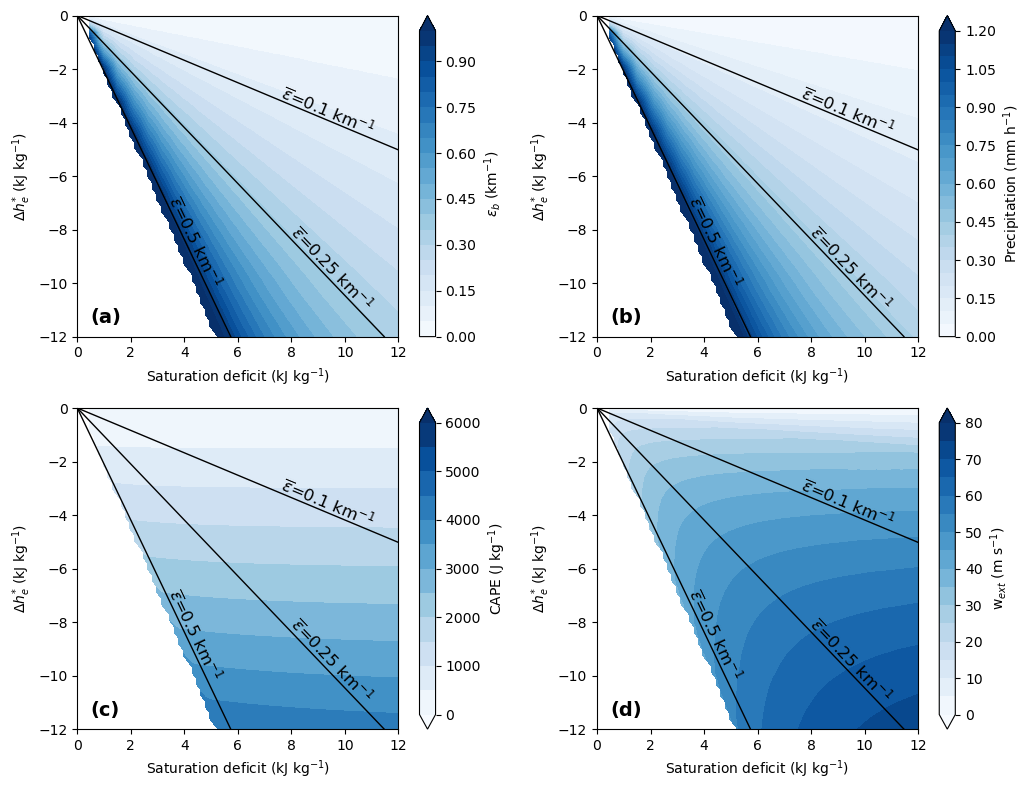

In [7]:

fig = plt.figure(figsize=(10.5,8))
ax4 = fig.add_subplot(221)
Xi, Yi, Zi = scatter_to_contour(sat_def_arr, dh_arr, ent_b_arr)
cf4 = ax4.contourf(Xi, Yi, Zi,levels=np.linspace(0,1,21),extend="max",cmap="Blues")
fig.colorbar(cf4, ax=ax4,label=r"$\epsilon_b$ (km$^{-1}$)")
for es,xval in zip([-0.5, -0.25,-0.1],[3.5,8.5,8.5]):
    yval = np.linspace(-12,0,20)
    xval1 = yval/(es)/dz
    
    plt.plot(xval1,yval,"k",linewidth=1)
    # slope dy/dx
    dy = yval[-1] - yval[0]
    dx = xval1[-1] - xval1[0]
    angle = np.degrees(np.arctan2(dy, dx))
    ix = np.argwhere(xval1<xval)[0][0]
    # choose a point ON the line for the label
    x_text = xval1[ix]
    y_text = yval[ix]
    if es == -0.25:
        x_text = xval1[ix+1]
        y_text = yval[ix+1]
    
    plt.text(
        x_text, y_text,
        r"$\overline{\epsilon}$"+f"={-es} km"+r"$^{-1}$",
        color="k",
        fontsize=12,
        rotation=angle+180,
        rotation_mode="anchor",
        transform_rotates_text=True,
        ha="left",
        va="bottom"
    )
ax4.set_xlim(0,12)
ax4.set_ylim(-12,0)
ax4.set_xlabel(r"Saturation deficit (kJ kg$^{-1}$)")
ax4.set_ylabel(r"$\Delta h_{e}^{*}$ (kJ kg$^{-1}$)")
ax4.text(0.5,-11.5,"(a)",fontweight="bold",fontsize=14)

ax4.set_aspect('equal')

ax1 = fig.add_subplot(222)
Xi, Yi, Zi = scatter_to_contour(sat_def_arr, dh_arr, np.array(P_list))
cf1 = ax1.contourf(Xi, Yi, Zi, levels=np.arange(0,1.25,0.05),extend="max",cmap="Blues")
fig.colorbar(cf1, ax=ax1, label="Precipitation (mm h$^{-1}$)")

for es,xval in zip([-0.5, -0.25,-0.1],[3.5,8.5,8.5]):
    yval = np.linspace(-12,0,20)
    xval1 = yval/(es)/dz
    
    plt.plot(xval1,yval,"k",linewidth=1)
    # slope dy/dx
    dy = yval[-1] - yval[0]
    dx = xval1[-1] - xval1[0]
    angle = np.degrees(np.arctan2(dy, dx))
    ix = np.argwhere(xval1<xval)[0][0]
    # choose a point ON the line for the label
    x_text = xval1[ix]
    y_text = yval[ix]
    if es == -0.25:
        x_text = xval1[ix+1]
        y_text = yval[ix+1]
    
    plt.text(
        x_text, y_text,
        r"$\overline{\epsilon}$"+f"={-es} km"+r"$^{-1}$",
        color="k",
        fontsize=12,
        rotation=angle+180,
        rotation_mode="anchor",
        transform_rotates_text=True,
        ha="left",
        va="bottom"
    )

ax1.set_xlim(0,12)
ax1.set_ylim(-12,0)
ax1.set_xlabel(r"Saturation deficit (kJ kg$^{-1}$)")
ax1.set_ylabel(r"$\Delta h_{e}^{*}$ (kJ kg$^{-1}$)")
ax1.text(0.5,-11.5,"(b)",fontweight="bold",fontsize=14)
ax1.set_aspect('equal')

ax2 = fig.add_subplot(223)
Xi, Yi, Zi = scatter_to_contour(sat_def_arr, dh_arr, CAPEu_list)
cf2 = ax2.contourf(Xi, Yi, Zi,levels=np.linspace(0,6000,13),extend="both",cmap="Blues")
fig.colorbar(cf2, ax=ax2,label=r"CAPE (J kg$^{-1}$)")
for es,xval in zip([-0.5, -0.25,-0.1],[3.5,8.5,8.5]):
    yval = np.linspace(-12,0,20)
    xval1 = yval/(es)/dz
    
    plt.plot(xval1,yval,"k",linewidth=1)
    # slope dy/dx
    dy = yval[-1] - yval[0]
    dx = xval1[-1] - xval1[0]
    angle = np.degrees(np.arctan2(dy, dx))
    ix = np.argwhere(xval1<xval)[0][0]
    # choose a point ON the line for the label
    x_text = xval1[ix]
    y_text = yval[ix]
    if es == -0.25:
        x_text = xval1[ix+1]
        y_text = yval[ix+1]
    
    plt.text(
        x_text, y_text,
        r"$\overline{\epsilon}$"+f"={-es} km"+r"$^{-1}$",
        color="k",
        fontsize=12,
        rotation=angle+180,
        rotation_mode="anchor",
        transform_rotates_text=True,
        ha="left",
        va="bottom"
    )
ax2.set_xlim(0,12)
ax2.set_ylim(-12,0)
ax2.set_xlabel(r"Saturation deficit (kJ kg$^{-1}$)")
ax2.set_ylabel(r"$\Delta h_{e}^{*}$ (kJ kg$^{-1}$)")
ax2.text(0.5,-11.5,"(c)",fontweight="bold",fontsize=14)

ax2.set_aspect('equal')

ax3 = fig.add_subplot(224)
Xi, Yi, Zi = scatter_to_contour(sat_def_arr, dh_arr, np.sqrt(2*CAPEext_list))
cf3 = ax3.contourf(Xi, Yi, Zi,levels=np.linspace(0,80,17),extend="both",cmap="Blues")
fig.colorbar(cf3, ax=ax3,label=r"w$_{ext}$ (m s$^{-1}$)")
for es,xval in zip([-0.5, -0.25,-0.1],[3.5,8.5,8.5]):
    yval = np.linspace(-12,0,20)
    xval1 = yval/(es)/dz
    
    plt.plot(xval1,yval,"k",linewidth=1)
    # slope dy/dx
    dy = yval[-1] - yval[0]
    dx = xval1[-1] - xval1[0]
    angle = np.degrees(np.arctan2(dy, dx))
    ix = np.argwhere(xval1<xval)[0][0]
    # choose a point ON the line for the label
    x_text = xval1[ix]
    y_text = yval[ix]
    if es == -0.25:
        x_text = xval1[ix+1]
        y_text = yval[ix+1]
    
    plt.text(
        x_text, y_text,
        r"$\overline{\epsilon}$"+f"={-es} km"+r"$^{-1}$",
        color="k",
        fontsize=12,
        rotation=angle+180,
        rotation_mode="anchor",
        transform_rotates_text=True,
        ha="left",
        va="bottom"
    )
ax3.set_xlim(0,12)
ax3.set_ylim(-12,0)
ax3.set_xlabel(r"Saturation deficit (kJ kg$^{-1}$)")
ax3.set_ylabel(r"$\Delta h_{e}^{*}$ (kJ kg$^{-1}$)")
ax3.text(0.5,-11.5,"(d)",fontweight="bold",fontsize=14)

ax3.set_aspect('equal')




# plt.suptitle(f"LCL = {z_lcl} m")
plt.tight_layout()

fig.savefig("Figures/Plume_spectrum_Palmer_plane.png",dpi=200,bbox_inches='tight')

---
## Learn more

- A full description of the SPM and methods can be found in [Lin and Singh et al. (2026)](https://doi.org/10.5194/wcd-7-2193-2026).
- More plotting scripts, the zero-buoyancy plume model by [Singh and O'Gorman (2013)](https://doi.org/10.1002/grl.50796), and the original spectral plume model by [Zhou and Xie (2019)](https://doi.org/10.1175/JAS-D-18-0330.1) can be found in the [plume_model](https://github.com/dongqi-DQ/plume_models/) repository.